# `cavanaulton/Squat-AI`: strength-comparison audit

**Classification: Level C — source review, with a separately labelled backend compatibility probe.** Reviewed at `e1f94988ba38dc979c27cb04cfbaa0ee1e481ed9` (2025-05-23). The application cannot run as cloned: it has a placeholder model path, no weights, imports Windows-only `winsound`, and its pinned Ultralytics 8.0.20 cannot deserialize the official pose checkpoint in the isolated environment.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
pd.set_option("display.max_colwidth", 100)

backend = json.loads((ROOT / "outputs/pose_backends/00001_yolov8_summary.json").read_text())
display(pd.Series(backend, name="separate backend probe").to_frame())

source_audit = pd.DataFrame([
    ("pose", "YOLO pose, expected 17 COCO keypoints", "not run in exact app"),
    ("side", "right shoulder/hip/knee/ankle only", "hard-coded"),
    ("knee angle", "hip–knee–ankle", "source formula"),
    ("'torso angle'", "hip–shoulder–knee", "not torso versus vertical as README says"),
    ("confidence gate", "> 0.3 for selected points", "source threshold"),
    ("depth bands", ">110 red; 90–110 amber; <=90 green", "source thresholds"),
    ("rep state", "count at <=90; reset at >110", "hysteresis"),
], columns=["area", "definition", "status"])
display(source_audit)

,separate backend probe
backend,"Ultralytics YOLOv8n-pose, CPU compatibility probe"
ultralytics,8.4.200
torch,2.1.2+cpu
opencv,4.8.1
device,cpu
frames,136
detected_frames,136
landmarks_per_detection,17
mean_latency_seconds,0.054481
mean_keypoint_confidence,0.842239


,area,definition,status
0,pose,"YOLO pose, expected 17 COCO keypoints",not run in exact app
1,side,right shoulder/hip/knee/ankle only,hard-coded
2,knee angle,hip–knee–ankle,source formula
3,'torso angle',hip–shoulder–knee,not torso versus vertical as README says
4,confidence gate,> 0.3 for selected points,source threshold
5,depth bands,>110 red; 90–110 amber; <=90 green,source thresholds
6,rep state,count at <=90; reset at >110,hysteresis


In [2]:
# Transparent re-expression of the source's threshold/state logic; this is not an app run.
angles = np.array([125, 112, 107, 98, 88, 84, 93, 108, 113, 119, 87, 116])
state = "up"; reps = 0; rows = []
for angle in angles:
    colour = "red" if angle > 110 else "amber" if angle > 90 else "green"
    if angle <= 90 and state == "up":
        reps += 1; state = "down"
    elif angle > 110 and state == "down":
        state = "up"
    rows.append((angle, colour, state, reps))
display(pd.DataFrame(rows, columns=["knee_angle", "band", "state", "rep_count"]))

,knee_angle,band,state,rep_count
0,125,red,up,0
1,112,red,up,0
2,107,amber,up,0
3,98,amber,up,0
4,88,green,down,1
5,84,green,down,1
6,93,amber,down,1
7,108,amber,down,1
8,113,red,up,1
9,119,red,up,1


## What transfers—and what does not

The useful patterns are confidence gating before geometry, an explicit side-view assumption, and hysteresis separating “entered” from “reset” states. A worker thread keeps camera inference off the PyQt event loop, although capture, inference, state, drawing, and sound remain tightly coupled inside one worker.

Do not transfer the literal squat thresholds to golf, the misnamed torso angle, single-side-only selection, or framewise unsmoothed decisions. There is no trajectory export, calibration, occlusion recovery, validation set, or medical/safety basis. No licence file exists in the clone; a README claim alone is not a legal grant.

The current-Ultralytics CPU probe processed all 136 golf frames with 17 points, but it is a version-deviating backend test—not evidence that Squat-AI runs. It also carries Ultralytics licensing implications that require project-specific review.

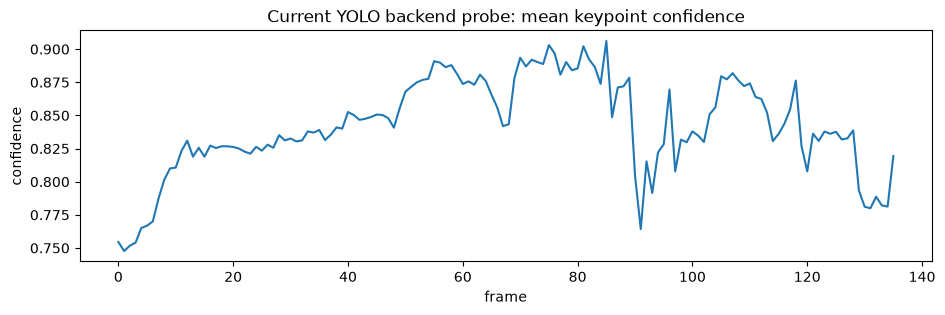

EXECUTED_OK: Squat-AI strength-comparison notebook


In [3]:
points = pd.read_csv(ROOT / "outputs/pose_backends/00001_yolov8_landmarks.csv")
per_frame = points.groupby("frame").confidence.mean()
per_frame.plot(figsize=(11, 3), title="Current YOLO backend probe: mean keypoint confidence")
plt.ylabel("confidence"); plt.show()
print("EXECUTED_OK: Squat-AI strength-comparison notebook")